# Frecuencias, clasificación y densidad de mutaciones en los genomas elegidos (2020–2024)

Este notebook se basa en los archivos de Nextclade (`nextclade_YYYY.tsv`) y el GFF3 del mismo dataset:

1. **Carga** los resultados de Nextclade con los filtros del proyecto.
2. **Clasifica** cada mutación de nucleótido como sinónima / no sinónima usando `aaSubstitutions` de Nextclade (traducción por codón completo y genes traslapados evaluados por separado).
3. **Calcula frecuencias** por año de mutaciones de nucleótidos y de aminoácidos.
4. **Calcula la densidad** de mutaciones por gen.
5. **Guarda** las tablas en `data/processed` y las gráficas en `results/images`.

El notebook debe ejecutarse desde la carpeta `notebooks/` del repositorio.

## 1. Librerías y configuración

In [14]:
import re
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

In [15]:
# Rutas relativas a la carpeta del repositorio (el notebook corre dentro de notebooks/).
base_dir = Path.cwd().parent

nextclade_dir = base_dir / "results" / "nextclade"
gff_path = base_dir / "data" / "sars-cov-2" / "genome_annotation.gff3"
out_dir = base_dir / "data" / "processed"
fig_dir = base_dir / "results" / "images"

print("Carpeta del repositorio:", base_dir.resolve())
if not gff_path.exists():
    raise FileNotFoundError(f"No encuentro el GFF3 en {gff_path.resolve()}: ¿el notebook está en la carpeta notebooks/?")

out_dir.mkdir(parents=True, exist_ok=True)
fig_dir.mkdir(parents=True, exist_ok=True)

years = [2020, 2021, 2022, 2023, 2024]

# Genomas que no deben entrar al análisis.
exclude = ["hCoV-19/Mexico/CMX-InDRE-01/2020|EPI_ISL_412972|2020-02-27"]

Carpeta del repositorio: C:\Users\cecil\OneDrive\Documents\GitHub\analisis_var_gene


## 2. Cargar Nextclade y el GFF3

`load_nextclade` aplica los dos filtros del proyecto. Todas las frecuencias se dividen entre el número de genomas que devuelve esta función (incluidos los que no tienen mutaciones).

In [16]:
def read_gff(path):
    """
    Lee el GFF3 de Nextclade y obtiene las coordenadas de cada gen.

    Parámetros
    ----------
    path : Path o str
        Ruta al archivo genome_annotation.gff3.

    Devuelve
    --------
    pd.DataFrame
        Una fila por gen con las columnas gene, start, end y length (en nt),
        ordenada por posición de inicio.
    """
    rows = []
    try:
        with open(path) as f:
            for line in f:
                if line.startswith("#") or not line.strip():
                    continue
                fields = line.rstrip("\n").split("\t")
                if len(fields) < 9 or fields[2] != "gene":
                    continue
                match = re.search(r"gene_name=([^;]+)", fields[8])
                if match is None:
                    print("Aviso: gen sin gene_name, se omite:", fields[8])
                    continue
                start, end = int(fields[3]), int(fields[4])
                rows.append({"gene": match.group(1).strip(), "start": start,
                             "end": end, "length": end - start + 1})   # GFF3: 1-based y cerrado
    except FileNotFoundError:
        raise FileNotFoundError(f"No existe el archivo GFF3: {path}")

    if not rows:
        raise ValueError(f"No se encontraron genes en {path}")
    return pd.DataFrame(rows).sort_values("start", ignore_index=True)


def load_nextclade(year):
    """
    Lee los resultados de Nextclade de un año y aplica los filtros del proyecto.

    Parámetros
    ----------
    year : int
        Año del archivo a leer (nextclade_<year>.tsv dentro de nextclade_dir).

    Devuelve
    --------
    pd.DataFrame
        Resultados de Nextclade.
    """
    path = nextclade_dir / f"nextclade_{year}.tsv"
    try:
        nc = pd.read_csv(path, sep="\t")
    except FileNotFoundError:
        raise FileNotFoundError(f"No existe el archivo de Nextclade: {path}")

    needed = ["seqName", "qc.overallStatus", "substitutions", "aaSubstitutions",
              "aaDeletions", "unknownAaRanges", "clade", "clade_who"]
    missing = [col for col in needed if col not in nc.columns]
    if missing:
        raise KeyError(f"A {path.name} le faltan las columnas: {missing}")

    nc = nc[~nc["seqName"].isin(exclude)]
    return nc.reset_index(drop=True)

In [17]:
gff_genes = read_gff(gff_path)

nc_by_year = {}
for year in years:
    try:
        nc_by_year[year] = load_nextclade(year)
    except (FileNotFoundError, KeyError) as error:
        print(f"Se omite {year}: {error}")

n_genomes = {year: len(nc) for year, nc in nc_by_year.items()}

print(gff_genes.to_string(index=False))
print("\nGenomas por año:", n_genomes)

 gene  start   end  length
ORF1a    266 13468   13203
ORF1b  13468 21555    8088
    S  21563 25384    3822
ORF3a  25393 26220     828
    E  26245 26472     228
    M  26523 27191     669
 ORF6  27202 27387     186
ORF7a  27394 27759     366
ORF7b  27756 27887     132
 ORF8  27894 28259     366
    N  28274 29533    1260
ORF9b  28284 28577     294

Genomas por año: {2020: 80, 2021: 80, 2022: 80, 2023: 80, 2024: 80}


## 3. Clasificar mutaciones (sinónimas / no sinónimas)

Para cada sustitución de nucleótido (`substitutions`) se calcula en qué gen y codón cae, y se pregunta si **ese mismo genoma** tiene un cambio de aminoácido en ese codón según `aaSubstitutions`:

| Si el codón… | Tipo |
|---|---|
| está en `unknownAaRanges` (datos faltantes) | `unknown` |
| está en `aaDeletions` | `deleted_codon` |
| tiene cambio en `aaSubstitutions` terminado en `*` | `nonsense` |
| tiene cambio en `aaSubstitutions` | `nonsynonymous` |
| no tiene cambio de aminoácido | `synonymous` |
| la posición no está en ningún gen | `noncoding` |

Por qué así y no traduciendo cada mutación contra la referencia:
- **Dos cambios en el mismo codón** (p. ej. G15016T + C15017T): Nextclade traduce el codón real del genoma (`TTA` → `ORF1b:A517L`); traducir una mutación a la vez inventaría `A517S` y `A517V`.
- **Genes traslapados** (N/ORF9b, ORF7a/ORF7b): una misma mutación se evalúa en **cada** gen que la contiene, por eso aparece en dos filas (p. ej. C28472T es `N:P67S` y sinónima en ORF9b).

In [18]:
def codons_in_ranges(text):
    """
    Convierte rangos de codones de Nextclade en un conjunto de (gen, codón).
    Se usa con la columna unknownAaRanges.

    Parámetros
    ----------
    text : str o NaN
        Rangos separados por comas, p. ej. 'S:158-160,S:373'.

    Devuelve
    --------
    set de tuplas
        p. ej. {('S', 158), ('S', 159), ('S', 160), ('S', 373)}.
        Conjunto vacío si el texto está vacío.
    """
    codons = set()
    if pd.isna(text):
        return codons
    for part in text.split(","):
        try:
            gene, span = part.split(":")
            start, end = (span.split("-") + [span])[:2]
            for codon in range(int(start), int(end) + 1):
                codons.add((gene, codon))
        except ValueError:
            print("Aviso: rango con formato inesperado, se omite:", part)
    return codons


def codons_with_change(text):
    """
    Indexa las mutaciones de aminoácido de Nextclade por (gen, codón).
    Se usa con las columnas aaSubstitutions y aaDeletions.

    Parámetros
    ----------
    text : str o NaN
        Mutaciones separadas por comas, p. ej. 'S:D614G,ORF1b:P314L'.

    Devuelve
    --------
    dict
        {(gen, codón): mutación}, p. ej. {('S', 614): 'S:D614G'}.
        Diccionario vacío si el texto está vacío.
    """
    changes = {}
    if pd.isna(text):
        return changes
    for mut in text.split(","):
        try:
            gene, rest = mut.split(":")
            changes[(gene, int(re.search(r"\d+", rest).group()))] = mut
        except (ValueError, AttributeError):
            print("Aviso: mutación con formato inesperado, se omite:", mut)
    return changes


def classify_mutations(nc_by_year, gff_genes):
    """
    Clasifica cada sustitución de nucleótido según el cambio de aminoácido
    que Nextclade reporta para ese mismo genoma.

    Parámetros
    ----------
    nc_by_year : dict
        {año: DataFrame de Nextclade ya filtrado (load_nextclade)}.
    gff_genes : pd.DataFrame
        Coordenadas de los genes (read_gff).

    Devuelve
    --------
    pd.DataFrame
        Una fila por (genoma, mutación de nt, gen) con las columnas seqName, year,
        clade, mutation, position, ref_nt, alt_nt, gene, codon, aa_mutation y type
        (synonymous, nonsynonymous, nonsense, unknown, deleted_codon o noncoding).
        Las mutaciones en genes traslapados aparecen una vez por gen.
    """
    rows = []
    for year, nc in nc_by_year.items():
        for _, rec in nc.iterrows():
            if pd.isna(rec["substitutions"]):
                continue                                   # genoma idéntico a Wuhan
            aa_changes = codons_with_change(rec["aaSubstitutions"])
            unknown = codons_in_ranges(rec["unknownAaRanges"])
            deleted = set(codons_with_change(rec["aaDeletions"]))

            for mut in rec["substitutions"].split(","):
                try:
                    pos = int(re.search(r"\d+", mut).group())
                except AttributeError:
                    print(f"Aviso: mutación sin posición en {rec['seqName']}, se omite:", mut)
                    continue
                base = {"seqName": rec["seqName"], "year": year, "clade": rec["clade"],
                        "mutation": mut, "position": pos,
                        "ref_nt": mut[0], "alt_nt": mut[-1]}
                hits = gff_genes[(gff_genes["start"] <= pos) & (gff_genes["end"] >= pos)]

                if hits.empty:
                    rows.append({**base, "gene": "intergenic", "codon": None,
                                 "aa_mutation": None, "type": "noncoding"})
                    continue

                for _, gene in hits.iterrows():            # una fila por cada gen que contiene la posición
                    codon = (pos - gene["start"]) // 3 + 1
                    key = (gene["gene"], codon)
                    if key in unknown:
                        aa, kind = None, "unknown"
                    elif key in deleted:
                        aa, kind = None, "deleted_codon"
                    elif key in aa_changes:
                        aa = aa_changes[key]
                        kind = "nonsense" if aa.endswith("*") else "nonsynonymous"
                    else:
                        aa, kind = None, "synonymous"
                    rows.append({**base, "gene": gene["gene"], "codon": codon,
                                 "aa_mutation": aa, "type": kind})

    if not rows:
        raise ValueError("No se encontró ninguna mutación: revisa los archivos de Nextclade.")
    df = pd.DataFrame(rows)
    df["codon"] = df["codon"].astype("Int64")              # entero que admite vacíos (intergénicas)
    return df


def summary_by_gene(df_muts):
    """
    Cuenta las mutaciones de cada tipo por gen.

    Parámetros
    ----------
    df_muts : pd.DataFrame
        Mutaciones clasificadas (classify_mutations).

    Devuelve
    --------
    pd.DataFrame
        Una fila por gen con el conteo de cada tipo, el total y frac_nonsyn
        (no sinónimas + sin sentido entre codificantes con tipo conocido).
        Las mutaciones en traslapes cuentan una vez en cada gen.
    """
    table = pd.crosstab(df_muts["gene"], df_muts["type"])
    table["total"] = table.sum(axis=1)
    nonsyn = table.get("nonsynonymous", 0) + table.get("nonsense", 0)
    syn = table.get("synonymous", 0)
    table["frac_nonsyn"] = (nonsyn / (nonsyn + syn)).round(3)
    return table.sort_values("total", ascending=False)

In [19]:
df_muts = classify_mutations(nc_by_year, gff_genes)
summary = summary_by_gene(df_muts)

try:
    df_muts.to_csv(out_dir / "nuevas_mutaciones_clasificadas.tsv", sep="\t", index=False)
    summary.to_csv(out_dir / "nuevo_resumen_por_gen.tsv", sep="\t")
except OSError as error:
    print("No se pudieron guardar las tablas:", error)

print(df_muts["type"].value_counts())
summary

type
nonsynonymous    18538
synonymous        5409
noncoding         1001
unknown             51
deleted_codon       12
nonsense             7
Name: count, dtype: int64


type,deleted_codon,noncoding,nonsense,nonsynonymous,synonymous,unknown,total,frac_nonsyn
gene,,,,,,,,
S,0,0,0,9380,563,51,9994,0.943
ORF1a,0,0,0,3213,2593,0,5806,0.553
ORF1b,0,0,0,1554,1091,0,2645,0.588
N,6,0,0,1730,152,0,1888,0.919
M,0,0,0,829,258,0,1087,0.763
intergenic,0,1001,0,0,0,0,1001,NaN
ORF3a,0,0,0,427,282,0,709,0.602
ORF6,0,0,0,384,159,0,543,0.707
ORF9b,6,0,0,399,15,0,420,0.964


## 4. Frecuencias por año

**Frecuencia = genomas con la mutación / genomas de ese año**.

Las dos funciones cuentan lo mismo: **cuántos genomas distintos** tienen cada mutación.

In [20]:
def nt_frequencies(df_muts, n_genomes):
    """
    Calcula la frecuencia por año de cada mutación de nucleótido, con una fila
    por cada gen donde cae (igual que la densidad y las mutaciones de aa).

    Parámetros
    ----------
    df_muts : pd.DataFrame
        Mutaciones clasificadas (classify_mutations).
    n_genomes : dict
        {año: número de genomas filtrados de ese año}.

    Devuelve
    --------
    pd.DataFrame
        Tabla larga con una fila por (year, mutation, gene) y las columnas
        n_genomes y frequency. Una mutación en un traslape (p. ej. C28311T
        en N y ORF9b) aparece en dos filas con la misma frecuencia: no sumes
        n_genomes sin quitar antes los duplicados de (year, mutation).
    """
    # nunique cuenta genomas distintos dentro de cada (año, mutación, gen).
    table = (df_muts.groupby(["year", "mutation", "gene"])["seqName"].nunique()
             .reset_index(name="n_genomes"))
    table["frequency"] = table["n_genomes"] / table["year"].map(n_genomes)
    return table.sort_values(["year", "frequency", "mutation"], ascending=[True, False, True],
                             ignore_index=True)


def aa_frequencies(nc_by_year):
    """
    Calcula la frecuencia por año de cada mutación de aminoácido (aaSubstitutions).

    Parámetros
    ----------
    nc_by_year : dict
        {año: DataFrame de Nextclade ya filtrado (load_nextclade)}.

    Devuelve
    --------
    pd.DataFrame
        Tabla larga con una fila por (year, aa_mutation) y las columnas
        gene, n_genomes y frequency.
    """
    rows = []
    for year, nc in nc_by_year.items():
        if len(nc) == 0:
            print(f"Aviso: {year} no tiene genomas, se omite.")
            continue
        counts = {}
        for aa_list in nc["aaSubstitutions"].dropna():
            for mut in set(aa_list.split(",")):            # cada genoma suma 1 por mutación
                counts[mut] = counts.get(mut, 0) + 1
        for mut, n in counts.items():
            rows.append({"year": year, "aa_mutation": mut, "gene": mut.split(":")[0],
                         "n_genomes": n, "frequency": n / len(nc)})
    table = pd.DataFrame(rows)
    return table.sort_values(["year", "frequency"], ascending=[True, False], ignore_index=True)


def to_wide(long_table, id_cols):
    """
    Pasa una tabla larga de frecuencias a una tabla mutación x año.

    Parámetros
    ----------
    long_table : pd.DataFrame
        Salida de nt_frequencies o aa_frequencies.
    id_cols : list
        Columnas que identifican cada mutación, p. ej. ["mutation", "gene"].

    Devuelve
    --------
    pd.DataFrame
        Una fila por mutación, una columna por año (0 si no apareció ese año)
        y max_frequency, ordenada de mayor a menor frecuencia máxima.
    """
    try:
        wide = long_table.pivot_table(index=id_cols, columns="year",
                                      values="frequency", fill_value=0)
    except KeyError as error:
        raise KeyError(f"Falta una columna para la tabla ancha: {error}")
    wide.columns.name = None
    wide["max_frequency"] = wide.max(axis=1)
    return wide.sort_values("max_frequency", ascending=False)

In [21]:
freq_nt = nt_frequencies(df_muts, n_genomes)
freq_aa = aa_frequencies(nc_by_year)

wide_nt = to_wide(freq_nt, ["mutation", "gene"])
wide_aa = to_wide(freq_aa, ["aa_mutation", "gene"])

try:
    wide_nt.round(4).to_csv(out_dir / "nuevas_frecuencias_nt_por_anio.tsv", sep="\t")
    wide_aa.round(4).to_csv(out_dir / "nuevas_frecuencias_aa_por_anio.tsv", sep="\t")
except OSError as error:
    print("No se pudieron guardar las tablas:", error)

print("Filas en la tabla nt:", len(wide_nt), "| mutaciones aa distintas:", len(wide_aa))
wide_aa.head(10).round(3)

Filas en la tabla nt: 2019 | mutaciones aa distintas: 1070


,,2020,2021,2022,2023,2024,max_frequency
aa_mutation,gene,,,,,,
ORF1b:P314L,ORF1b,0.938,1.000,1.000,1.00,1.000,1.000
ORF1a:T3255I,ORF1a,0.038,0.712,1.000,0.95,0.925,1.000
S:D614G,S,0.938,1.000,1.000,1.00,1.000,1.000
S:T478K,S,0.025,0.925,0.988,0.95,0.950,0.988
S:S375F,S,0.000,0.062,0.875,0.95,0.925,0.950
M:A63T,M,0.000,0.075,0.900,0.95,0.925,0.950
S:S477N,S,0.000,0.075,0.900,0.95,0.925,0.950
S:S373P,S,0.000,0.062,0.888,0.95,0.925,0.950
S:Y505H,S,0.000,0.075,0.875,0.95,0.925,0.950


## 5. Densidad de mutaciones por gen

**Densidad = mutaciones de nt únicas en el gen (2020–2024) / longitud del gen × 1000** (mutaciones por kb).

In [22]:
def density_by_gene(df_muts, gff_genes):
    """
    Calcula la densidad de mutaciones de nucleótido por gen (todos los años juntos).

    Parámetros
    ----------
    df_muts : pd.DataFrame
        Mutaciones clasificadas (classify_mutations).
    gff_genes : pd.DataFrame
        Coordenadas y longitud de los genes (read_gff).

    Devuelve
    --------
    pd.DataFrame
        Una fila por gen con length_nt, unique_mutations y mutations_per_kb,
        ordenada de mayor a menor densidad.
    """
    in_genes = df_muts[df_muts["gene"] != "intergenic"]
    unique = in_genes.groupby("gene")["mutation"].nunique().rename("unique_mutations")
    table = gff_genes.set_index("gene")[["length"]].rename(columns={"length": "length_nt"})
    table = table.join(unique).fillna({"unique_mutations": 0})
    table["unique_mutations"] = table["unique_mutations"].astype(int)
    table["mutations_per_kb"] = (table["unique_mutations"] / table["length_nt"] * 1000).round(2)
    return table.sort_values("mutations_per_kb", ascending=False)

In [23]:
density = density_by_gene(df_muts, gff_genes)

try:
    density.to_csv(out_dir / "nueva_densidad_por_gen.tsv", sep="\t")
except OSError as error:
    print("No se pudo guardar la tabla:", error)

density

,length_nt,unique_mutations,mutations_per_kb
gene,,,
N,1260,148,117.46
ORF3a,828,94,113.53
ORF9b,294,32,108.84
ORF8,366,32,87.43
ORF6,186,16,86.02
ORF7a,366,31,84.70
S,3822,316,82.68
M,669,48,71.75
E,228,14,61.40


## 6. Gráficas

Agrupa las siguientes funciones:

- `plot_by_gene`: heatmap de mutaciones nt únicas por gen y año + barras de densidad por kb.
- `plot_top_shared`: evolución de las 10 mutaciones nt (dentro de genes) presentes en todos los años.
- `plot_variants`: proporción de variantes (`clade_who`) por año.

In [24]:
def save_figure(fig, name):
    """
    Guarda una figura en fig_dir y la muestra.

    Parámetros
    ----------
    fig : matplotlib.figure.Figure
        Figura a guardar.
    name : str
        Nombre del archivo, p. ej. "densidad_por_gen.png".

    Devuelve
    --------
    None
    """
    fig.tight_layout()
    try:
        fig.savefig(fig_dir / name, dpi=300)
    except OSError as error:
        print(f"No se pudo guardar {name}:", error)
    finally:    
        plt.show()
        plt.close(fig)


def plot_by_gene(df_muts, density):
    """
    Grafica las mutaciones por gen: un heatmap de mutaciones nt únicas por gen y año,
    y un gráfico de barras con la densidad de mutaciones por kb.

    Parámetros
    ----------
    df_muts : pd.DataFrame
        Mutaciones clasificadas (classify_mutations).
    density : pd.DataFrame
        Densidad por gen (density_by_gene), con la columna mutations_per_kb.

    Devuelve
    --------
    pd.DataFrame
        Tabla gen x año con el número de mutaciones nt únicas (la que se usa en el heatmap).
    """
    try:
        unique_by_gene_year = (df_muts[df_muts["gene"] != "intergenic"]
                               .groupby(["gene", "year"])["mutation"].nunique()
                               .unstack(fill_value=0))
        ordered = density.sort_values("mutations_per_kb")
    except KeyError as error:
        raise KeyError(f"Falta una columna para graficar por gen: {error}")
    unique_by_gene_year = unique_by_gene_year.loc[
        unique_by_gene_year.sum(axis=1).sort_values(ascending=False).index]
    period = f"{df_muts['year'].min()}–{df_muts['year'].max()}"

    # Heatmap: una fila por gen, una columna por año.
    fig, ax = plt.subplots(figsize=(6, 0.4 * len(unique_by_gene_year) + 1))
    im = ax.imshow(unique_by_gene_year.values, aspect="auto", cmap="GnBu")
    ax.set_xticks(range(len(unique_by_gene_year.columns)))
    ax.set_xticklabels(unique_by_gene_year.columns)
    ax.set_yticks(range(len(unique_by_gene_year)))
    ax.set_yticklabels(unique_by_gene_year.index)
    threshold = unique_by_gene_year.values.max() / 2
    for i in range(unique_by_gene_year.shape[0]):
        for j in range(unique_by_gene_year.shape[1]):
            value = unique_by_gene_year.iloc[i, j]
            ax.text(j, i, value, ha="center", va="center", fontsize=9,
                    color="white" if value > threshold else "black")
    fig.colorbar(im, label="Total")
    ax.set_xlabel("Año")
    ax.set_ylabel("Gen")
    ax.set_title("Mutaciones de nucleótidos únicas por gen y año")
    save_figure(fig, "heatmap_mutaciones_por_gen.png")

    # Barras: densidad por kb (todos los años juntos).
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.barh(ordered.index, ordered["mutations_per_kb"], color="#A50F15")
    ax.set_xlabel(f"Mutaciones únicas por kb ({period})")
    ax.set_ylabel("Gen")
    ax.set_title(f"Densidad de mutaciones por gen ({period})")
    save_figure(fig, "densidad_por_gen.png")

    return unique_by_gene_year


def plot_top_shared(wide_nt, years, n_top=10):
    """
    Grafica la evolución de las mutaciones nt (dentro de genes) presentes en
    todos los años, ordenadas por su frecuencia promedio. Las mutaciones con
    exactamente la misma frecuencia todos los años (heredadas juntas) se dibujan
    como una sola línea con todas sus etiquetas.

    Parámetros
    ----------
    wide_nt : pd.DataFrame
        Tabla ancha de frecuencias nt (to_wide), con índice (mutation, gene).
    years : list
        Años a considerar.
    n_top : int, opcional
        Número de líneas (trayectorias distintas) a graficar (10 por defecto).

    Devuelve
    --------
    pd.DataFrame
        Una fila por línea graficada: frecuencias por año y la columna mutations
        con las mutaciones que comparten esa trayectoria.
    """
    year_cols = [y for y in years if y in wide_nt.columns]
    if not year_cols:
        raise ValueError("Ningún año de `years` está en la tabla de frecuencias.")
    in_genes = wide_nt[wide_nt.index.get_level_values("gene") != "intergenic"][year_cols]

    # 1) Una fila por mutación: en traslapes (N y ORF9b) ambas filas tienen la misma frecuencia.
    gene_labels = (in_genes.reset_index().groupby("mutation")["gene"]
                   .agg(lambda g: "/".join(sorted(set(g)))))
    in_genes = in_genes.groupby(level="mutation").first()

    shared = in_genes[(in_genes > 0).all(axis=1)]
    if shared.empty:
        print("Aviso: ninguna mutación está presente en todos los años.")
        return shared

    # 2) Agrupar mutaciones con la misma trayectoria (mismas frecuencias todos los años).
    labels = [f"{mut} ({gene_labels[mut]})" for mut in shared.index]
    trajectories = (shared.round(4).assign(label=labels)
                    .groupby(year_cols, as_index=False)["label"]
                    .agg(" + ".join)
                    .rename(columns={"label": "mutations"}))

    # 3) Las n_top trayectorias con mayor frecuencia promedio.
    trajectories["mean"] = trajectories[year_cols].mean(axis=1)
    top = trajectories.sort_values("mean", ascending=False).head(n_top).drop(columns="mean")

    fig, ax = plt.subplots(figsize=(9, 5))
    for _, row in top.iterrows():
        ax.plot(year_cols, row[year_cols].values.astype(float), marker="o",
                label=row["mutations"].replace(" + ", "\n"))    # una mutación por renglón
    ax.set_xticks(year_cols)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("Año")
    ax.set_ylabel("Frecuencia (proporción de genomas)")
    ax.set_title(f"Evolución de las mutaciones de nucleótido más frecuentes\n"
                 f"presentes en todos los años ({len(top)} trayectorias)")
    ax.legend(title="Mutación (gen)", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
    save_figure(fig, f"top{n_top}_nt_comunes.png")
    return top


def plot_variants(nc_by_year):
    """
    Grafica la proporción de genomas de cada variante (clade_who) por año
    en barras apiladas.

    Parámetros
    ----------
    nc_by_year : dict
        {año: DataFrame de Nextclade ya filtrado (load_nextclade)}.

    Devuelve
    --------
    pd.DataFrame
        Proporción de cada variante por año (filas = años).
    """
    try:
        variants = pd.concat(
            [nc.assign(year=year)[["year", "clade_who"]] for year, nc in nc_by_year.items()],
            ignore_index=True,
        )
    except (KeyError, ValueError) as error:
        raise ValueError(f"No se pudo armar la tabla de variantes: {error}")
    variants["variant"] = variants["clade_who"].fillna("Otro")
    proportions = pd.crosstab(variants["year"], variants["variant"], normalize="index")

    fig, ax = plt.subplots(figsize=(7, 5))
    proportions.plot(kind="bar", stacked=True, ax=ax)
    ax.set_ylabel("Proporción de genomas")
    ax.set_xlabel("Año")
    ax.set_title("Distribución de variantes de SARS-CoV-2 por año")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="Variante (OMS)", bbox_to_anchor=(1.02, 1), loc="upper left")
    save_figure(fig, "variantes_por_anio.png")
    return proportions

def plot_aa_changes(wide_aa, years, n_top, cmap="Blues"):
    """
    Grafica un heatmap con las mutaciones de aminoácido cuya frecuencia varió más con el
    paso de los años.

    Parámetros
    ----------
    wide_aa : pd.DataFrame
        Tabla ancha de frecuencias aa (to_wide), con índice (aa_mutation, gene).
    years : list
        Años a considerar.
    n_top : int, opcional
        Número de mutaciones a graficar (25 por defecto).
    cmap : str, opcional
        Escala de color de matplotlib ("Blues" por defecto).

    Devuelve
    --------
    pd.DataFrame
        Frecuencias por año de las mutaciones graficadas, con la columna change.
    """
    year_cols = [y for y in years if y in wide_aa.columns]
    if len(year_cols) < 2:
        raise ValueError("Se necesitan al menos dos años para ver cambios en el tiempo.")

    freqs = wide_aa[year_cols].copy()
    freqs.index = freqs.index.get_level_values("aa_mutation")
    freqs["change"] = freqs.max(axis=1) - freqs.min(axis=1)
    top = freqs.sort_values("change", ascending=False).head(n_top)

    # Orden cronológico: primero las que alcanzan una alta frecuencia con mayor rapidez.
    peak_year = top[year_cols].idxmax(axis=1)
    top = top.assign(peak_year=peak_year).sort_values(["peak_year", "change"],
                                                     ascending=[True, False])
    values = top[year_cols]

    fig, ax = plt.subplots(figsize=(6, 0.3 * len(values) + 1.5))
    im = ax.imshow(values.values, aspect="auto", cmap=cmap, vmin=0, vmax=1)
    ax.set_xticks(range(len(year_cols)))
    ax.set_xticklabels(year_cols)
    ax.set_yticks(range(len(values)))
    ax.set_yticklabels(values.index, fontsize=8)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            v = values.iloc[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if v > 0.5 else "black")
    fig.colorbar(im, label="Frecuencia")
    ax.set_xlabel("Año")
    ax.set_title("Mutaciones de aminoácidos con mayor cambio de frecuencia\n")
    save_figure(fig, f"top{n_top}_aa_cambio_frecuencia.png")
    return top.drop(columns="peak_year")


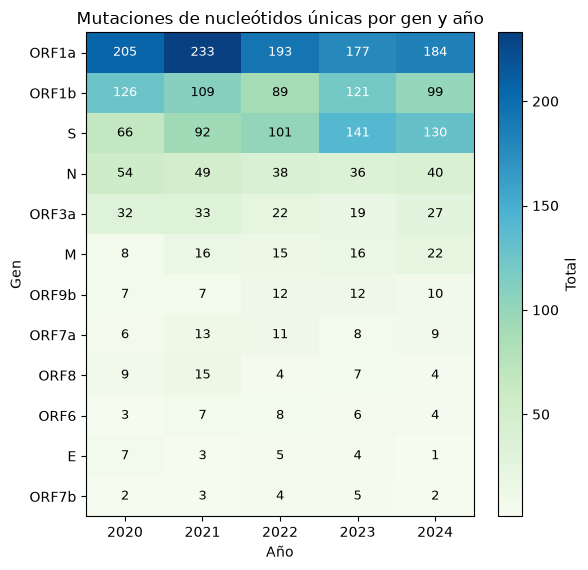

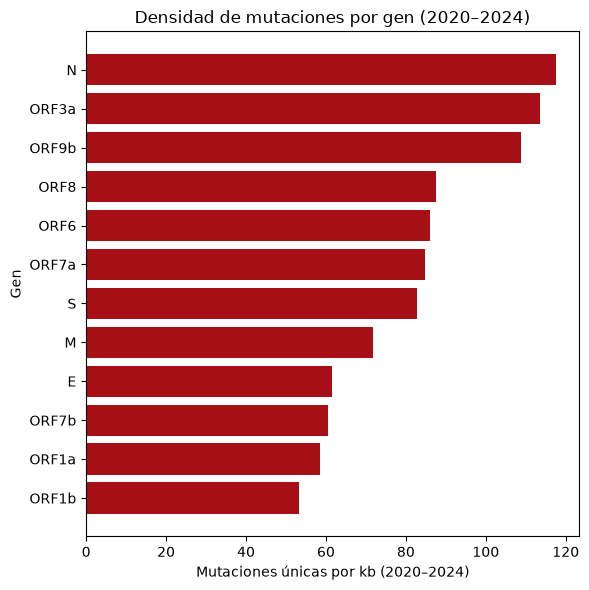

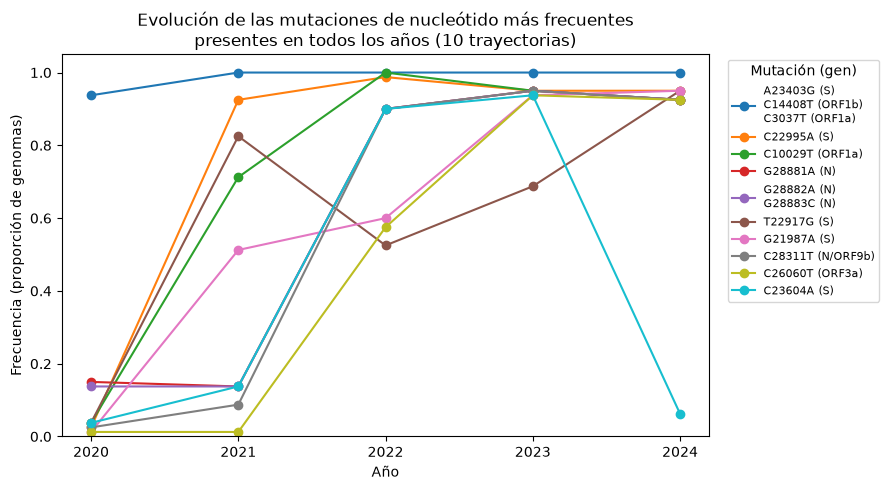

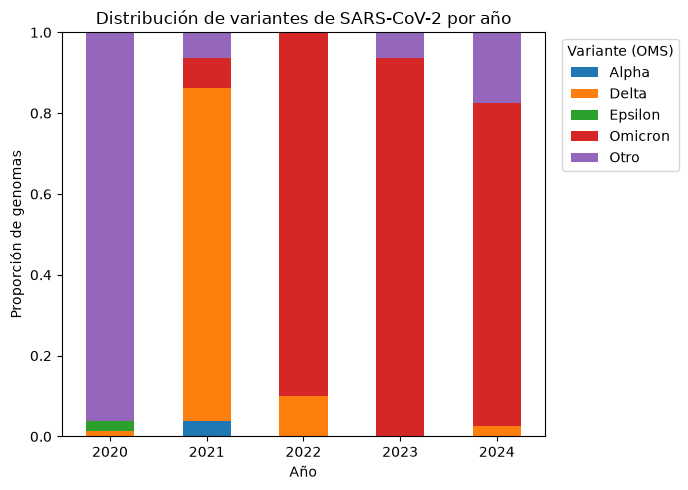

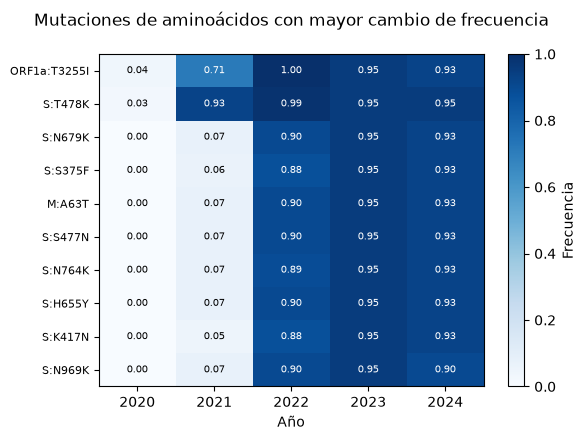

     2020   2021   2022   2023   2024  \
15  0.938  1.000  1.000  1.000  1.000   
7   0.025  0.925  0.988  0.950  0.950   
10  0.038  0.712  1.000  0.950  0.925   
14  0.150  0.138  0.900  0.950  0.925   
13  0.138  0.138  0.900  0.950  0.925   
11  0.038  0.825  0.525  0.688  0.950   
2   0.012  0.512  0.600  0.938  0.950   
5   0.025  0.088  0.900  0.950  0.925   
0   0.012  0.012  0.575  0.938  0.925   
9   0.038  0.138  0.900  0.938  0.062   

                                         mutations  
15  A23403G (S) + C14408T (ORF1b) + C3037T (ORF1a)  
7                                      C22995A (S)  
10                                 C10029T (ORF1a)  
14                                     G28881A (N)  
13                       G28882A (N) + G28883C (N)  
11                                     T22917G (S)  
2                                      G21987A (S)  
5                                C28311T (N/ORF9b)  
0                                  C26060T (ORF3a)  
9                 

In [25]:
unique_by_gene_year = plot_by_gene(df_muts, density)
top10 = plot_top_shared(wide_nt, years, n_top=10)
proportions = plot_variants(nc_by_year)
aa_changes = plot_aa_changes(wide_aa, years, n_top=10)
print(top10.round(3))